# Build a Transformer Embedding Model From Scratch
**Data → vocabulary → tokenizer → transformer → embeddings → semantic search / Q&A**

| Stage | What we build | Well-known dataset | How we verify |
|---|---|---|---|
| 1 | Corpus cleaning | WikiText-103 | size / statistics |
| 2 | BPE tokenizer + vocabulary (pure Python) | WikiText-103 | compare with BERT's WordPiece vocab, Zipf curve |
| 3 | Transformer encoder + masked-language-model pre-training | WikiText-103 | loss curve, fill-in-the-blank |
| 4 | Sentence embeddings via contrastive learning | all-NLI | **STS-Benchmark** Spearman (published numbers exist) |
| 5 | Semantic search / Q&A retriever | SQuAD v1.1 (dev) | Recall@k, MRR vs. a BM25 baseline |

Run top to bottom. Pick a preset in the next cell: `quick` (~20-30 min, shows the whole pipeline works) or `standard` (a few hours, better numbers).

In [1]:
%pip install -q datasets tokenizers matplotlib scikit-learn scipy

Note: you may need to restart the kernel to use updated packages.


In [2]:
%pip install torch

Note: you may need to restart the kernel to use updated packages.


In [3]:
import os, re, json, math, time, random, unicodedata, heapq
from collections import Counter, defaultdict
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from scipy.sparse import csr_matrix
from datasets import load_dataset

PRESET = os.environ.get("PRESET", "quick")      # "quick" | "standard"  ("smoke" = tiny code check)
PRESETS = {
  "smoke":    dict(lines=3000,  vocab_size=600,  min_char=5,  min_word=1, d_model=64,  n_layers=2, n_heads=2, d_ff=128,  max_len=64,
                   mlm_steps=30,  mlm_bs=16,  lr=1e-3, nli_rows=600,  ft_steps=20,  ft_bs=16,  squad_q=100,  tsne_n=300),
  "quick":    dict(lines=150_000, vocab_size=8000,  min_char=50, min_word=3, d_model=256, n_layers=4, n_heads=4, d_ff=1024, max_len=128,
                   mlm_steps=4000, mlm_bs=128, lr=8e-4, nli_rows=100_000, ft_steps=800, ft_bs=128, squad_q=3000, tsne_n=3000),
  "standard": dict(lines=None,    vocab_size=16000, min_char=50, min_word=3, d_model=384, n_layers=6, n_heads=6, d_ff=1536, max_len=128,
                   mlm_steps=30000, mlm_bs=128, lr=5e-4, nli_rows=None, ft_steps=4300, ft_bs=128, squad_q=None, tsne_n=6000),
}
P = PRESETS[PRESET]
SEED = 42; random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
BF16 = DEVICE == "cuda" and torch.cuda.get_device_capability()[0] >= 8      # RTX 3050 (Ampere) -> bf16, Colab T4 -> fp16
AMP_DTYPE = torch.bfloat16 if BF16 else torch.float16
def amp(): return torch.autocast(device_type="cuda", dtype=AMP_DTYPE, enabled=(DEVICE == "cuda"))
OUT = "artifacts"; os.makedirs(OUT, exist_ok=True)
METRICS, CURVES = {"preset": PRESET, "config": P}, {}
print(PRESET, "| device:", DEVICE, "| dtype:", AMP_DTYPE if DEVICE == "cuda" else "fp32",
      "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")
# If you get a CUDA out-of-memory error (e.g. 4 GB GPU), lower mlm_bs / ft_bs in the preset.

c:\Users\uttha\OneDrive\Desktop\scratch\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


quick | device: cpu | dtype: fp32 | 


## 1. Dataset: WikiText-103
~103M words of curated Wikipedia articles, a standard language-modelling benchmark. The raw version keeps original casing.
We drop section headings and undo WikiText's `@-@` number/hyphen markers.

In [4]:
raw = list(load_dataset("Salesforce/wikitext", "wikitext-103-raw-v1", split="train")["text"])
def clean_line(s):
    s = s.strip()
    if not s or s.startswith("="): return None            # blank lines and "= Heading =" lines
    return s.replace(" @-@ ", "-").replace(" @,@ ", ",").replace(" @.@ ", ".")
lines = [c for c in map(clean_line, raw[:P["lines"]] if P["lines"] else raw) if c]
del raw
print(f"{len(lines):,} paragraphs | {sum(len(l.split()) for l in lines)/1e6:.1f}M words")
print(lines[3][:300])

71,600 paragraphs | 8.0M words
As with previous Valkyira Chronicles games , Valkyria Chronicles III is a tactical role-playing game where players take control of a military unit and take part in missions against enemy forces . Stories are told through comic book-like panels with animated character portraits , with characters spea


## 2. Tokenizer + vocabulary, from scratch
**Byte-pair encoding (BPE):** start with single characters, repeatedly merge the most frequent adjacent pair into a new token.
We use BERT's notation: a word's first piece is bare (`play`), later pieces carry `##` (`##ing`).
Rare words are split into known pieces, so there are almost no unknown words.

In [5]:
PRETOK = re.compile(r"\w+|[^\w\s]", re.UNICODE)
def normalize(t): return unicodedata.normalize("NFKC", t).lower()
def pretokenize(t): return PRETOK.findall(normalize(t))
SPECIALS = ["[PAD]", "[UNK]", "[CLS]", "[SEP]", "[MASK]"]; PAD, UNK, CLS, SEP, MASK = range(5); N_SPECIAL = 5

class BPETokenizer:
    def __init__(self, vocab, merges):
        self.vocab, self.merges = vocab, merges
        self.tok2id = {t: i for i, t in enumerate(vocab)}
        self.ranks = {tuple(m): i for i, m in enumerate(merges)}
        self.cache = {}

    @classmethod
    def train(cls, word_counts, vocab_size, min_char=50, min_word=3, verbose=True):
        char_cnt = Counter()
        for w, c in word_counts.items():
            for ch in w: char_cnt[ch] += c
        alphabet = sorted(ch for ch, c in char_cnt.items() if c >= min_char)
        aset = set(alphabet)
        vocab = list(SPECIALS) + alphabet + ["##" + c for c in alphabet]; seen = set(vocab)
        words = [(w, c) for w, c in word_counts.items() if c >= min_word and all(ch in aset for ch in w)]
        W = [[w[0]] + ["##" + ch for ch in w[1:]] for w, _ in words]; Fq = [c for _, c in words]
        pc, where = defaultdict(int), defaultdict(set)
        for i, syms in enumerate(W):
            for p in zip(syms, syms[1:]): pc[p] += Fq[i]; where[p].add(i)
        heap = [(-c, p) for p, c in pc.items()]; heapq.heapify(heap); merges = []
        while len(vocab) < vocab_size and heap:
            negc, pair = heapq.heappop(heap); cur = pc.get(pair, 0)
            if cur != -negc:                                   # stale heap entry -> refresh
                if cur > 0: heapq.heappush(heap, (-cur, pair))
                continue
            if cur < 2: break
            a, b = pair; merged = a + b[2:]; changed = set()
            for i in list(where[pair]):
                syms = W[i]; new = []; j = 0
                while j < len(syms):
                    if j < len(syms) - 1 and syms[j] == a and syms[j + 1] == b: new.append(merged); j += 2
                    else: new.append(syms[j]); j += 1
                if len(new) == len(syms): continue
                for p in zip(syms, syms[1:]): pc[p] -= Fq[i]
                for p in zip(new, new[1:]): pc[p] += Fq[i]; where[p].add(i); changed.add(p)
                W[i] = new
            pc.pop(pair, None); where.pop(pair, None)
            for p in changed:
                if pc[p] > 0: heapq.heappush(heap, (-pc[p], p))
            merges.append(pair)
            if merged not in seen: seen.add(merged); vocab.append(merged)
            if verbose and len(merges) % 2000 == 0: print(f"  {len(merges):>6} merges, vocab {len(vocab)}, last: {a} + {b} -> {merged}")
        return cls(vocab, merges)

    def _word(self, w):
        syms = [w[0]] + ["##" + c for c in w[1:]]
        while len(syms) > 1:
            best, br = None, 1e18
            for i in range(len(syms) - 1):
                r = self.ranks.get((syms[i], syms[i + 1]))
                if r is not None and r < br: br, best = r, i
            if best is None: break
            syms[best:best + 2] = [syms[best] + syms[best + 1][2:]]
        ids = [self.tok2id.get(s, UNK) for s in syms]
        ids = [UNK] if UNK in ids else ids                      # any unknown char -> whole word [UNK] (like BERT)
        self.cache[w] = ids; return ids

    def encode_words(self, text):
        out = []; cache = self.cache
        for w in pretokenize(text): out.extend(cache.get(w) or self._word(w))
        return out

    def encode(self, text, max_len=None, add_special=True):
        ids = []
        for piece in re.split(r"(\[MASK\])", text):             # allow a literal [MASK] in the text
            ids.extend([MASK] if piece == "[MASK]" else self.encode_words(piece))
        if add_special:
            ids = ids[: (max_len - 2) if max_len else None]; ids = [CLS] + ids + [SEP]
        return ids

    def tokenize(self, text): return [self.vocab[i] for i in self.encode(text, add_special=False)]
    def decode(self, ids): return " ".join(self.vocab[i] for i in ids)
    def save(self, path): json.dump({"vocab": self.vocab, "merges": self.merges}, open(path, "w"))
    @classmethod
    def load(cls, path): d = json.load(open(path)); return cls(d["vocab"], [tuple(m) for m in d["merges"]])

In [6]:
t0 = time.time(); word_counts = Counter()
for i in range(0, len(lines), 50_000): word_counts.update(pretokenize("\n".join(lines[i:i + 50_000])))
print(f"{len(word_counts):,} distinct words, {sum(word_counts.values())/1e6:.1f}M total ({time.time()-t0:.0f}s)")
tok = BPETokenizer.train(word_counts, P["vocab_size"], P["min_char"], P["min_word"])
tok.save(f"{OUT}/tokenizer.json"); VOCAB = len(tok.vocab)
print("vocab size:", VOCAB, f"| trained in {time.time()-t0:.0f}s")
for s in ["The Eiffel Tower is located in Paris.", "Unbelievably, transformers tokenize antidisestablishmentarianism!"]:
    print(tok.tokenize(s))

136,698 distinct words, 8.3M total (5s)
    2000 merges, vocab 2319, last: qu + ##ick -> quick
    4000 merges, vocab 4319, last: 2 + ##nd -> 2nd
    6000 merges, vocab 6319, last: ter + ##ror -> terror
vocab size: 8000 | trained in 10s
['the', 'e', '##iff', '##el', 'tower', 'is', 'located', 'in', 'paris', '.']
['un', '##b', '##el', '##ie', '##v', '##ably', ',', 'transform', '##ers', 'to', '##ken', '##ize', 'ant', '##id', '##is', '##est', '##ab', '##lish', '##ment', '##arian', '##ism', '!']


### Verify the vocabulary
1. **Zipf's law** - token frequencies should fall on a near straight line in log-log space.
2. **Fertility** - average pieces per word (BERT's WordPiece is ≈1.2-1.4 on English text).
3. **Compare with `bert-base-uncased`** - same `##` notation, so we can measure vocabulary overlap directly.

10.3M tokens (5s)
fertility 1.24 tokens/word | [UNK] rate 0.0392%


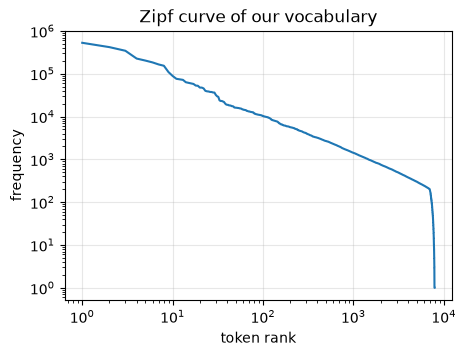

10 most frequent tokens: ['the', ',', '.', 'of', 'and', 'in', 'to', 'a', '"', 'was']


In [7]:
def encode_corpus(lines, chunk=20_000):
    out = []
    for i in range(0, len(lines), chunk):
        ids = []
        for l in lines[i:i + chunk]: ids.extend(tok.encode_words(l)); ids.append(SEP)
        out.append(np.array(ids, dtype=np.uint16))
    return np.concatenate(out)
t0 = time.time(); stream = encode_corpus(lines); print(f"{len(stream)/1e6:.1f}M tokens ({time.time()-t0:.0f}s)")
freq = np.bincount(stream, minlength=VOCAB)
n_words = sum(word_counts.values()); fert = (len(stream) - len(lines)) / n_words
unk_rate = freq[UNK] / len(stream)
print(f"fertility {fert:.2f} tokens/word | [UNK] rate {unk_rate:.4%}")
METRICS["tokenizer"] = dict(vocab_size=VOCAB, fertility=float(fert), unk_rate=float(unk_rate), corpus_tokens=int(len(stream)))

top = np.sort(freq[N_SPECIAL:])[::-1]; top = top[top > 0]
plt.figure(figsize=(5, 3.5)); plt.loglog(np.arange(1, len(top) + 1), top); plt.xlabel("token rank"); plt.ylabel("frequency")
plt.title("Zipf curve of our vocabulary"); plt.grid(alpha=.3); plt.show()
print("10 most frequent tokens:", [tok.vocab[i] for i in np.argsort(-freq)[:10]])

In [8]:
stsb = {s: load_dataset("sentence-transformers/stsb", split=s) for s in ["validation", "test"]}
sample = list(stsb["test"]["sentence1"])[:500]
try:
    from tokenizers import Tokenizer
    bert = Tokenizer.from_pretrained("bert-base-uncased")
    bert_vocab = set(bert.get_vocab())
    overlap = len(bert_vocab & set(tok.vocab)) / VOCAB
    nw = sum(len(pretokenize(s)) for s in sample)
    f_ours = sum(len(tok.encode_words(s)) for s in sample) / nw
    f_bert = sum(len(bert.encode(s, add_special_tokens=False).ids) for s in sample) / nw
    print(f"{overlap:.0%} of our vocab also appears in BERT's | fertility on STS-B text: ours {f_ours:.2f} vs BERT {f_bert:.2f}")
    s = "The cat sat on the mat while astronomers observed exoplanets."
    print("ours:", tok.tokenize(s)); print("bert:", bert.encode(s, add_special_tokens=False).tokens)
    METRICS["tokenizer"].update(bert_overlap=float(overlap), fertility_ours_stsb=f_ours, fertility_bert_stsb=f_bert)
except Exception as e: print("BERT comparison skipped:", e)

77% of our vocab also appears in BERT's | fertility on STS-B text: ours 1.18 vs BERT 1.02
ours: ['the', 'cat', 'sat', 'on', 'the', 'mat', 'while', 'astronom', '##ers', 'observed', 'ex', '##op', '##lan', '##ets', '.']
bert: ['the', 'cat', 'sat', 'on', 'the', 'mat', 'while', 'astronomers', 'observed', 'ex', '##op', '##lane', '##ts', '.']


## 3. The transformer encoder (written with plain PyTorch layers)
Token embedding + position embedding → N × [self-attention → feed-forward] with residual connections and LayerNorm.
Self-attention: `softmax(QKᵀ/√d)·V`, run in several heads. Padding positions are masked out.
The "manual" attention path (used when we want to *see* attention) is checked against PyTorch's fused kernel below.

In [9]:
class Attention(nn.Module):
    def __init__(s, d, h, p):
        super().__init__(); s.h, s.dh, s.p = h, d // h, p
        s.qkv, s.out = nn.Linear(d, 3 * d), nn.Linear(d, d)
    def forward(s, x, keep, return_attn=False):                 # keep: (B,T) bool, True = real token
        B, T, _ = x.shape
        q, k, v = s.qkv(x).view(B, T, 3, s.h, s.dh).permute(2, 0, 3, 1, 4)
        if return_attn:                                         # explicit formula
            sc = (q @ k.transpose(-2, -1)) / math.sqrt(s.dh)
            sc = sc.masked_fill(~keep[:, None, None, :], float("-inf"))
            a = sc.softmax(-1); o = F.dropout(a, s.p, s.training) @ v
        else:                                                   # same maths, fused kernel
            a = None; o = F.scaled_dot_product_attention(q, k, v, attn_mask=keep[:, None, None, :], dropout_p=s.p if s.training else 0.0)
        return s.out(o.transpose(1, 2).reshape(B, T, -1)), a

class Block(nn.Module):
    def __init__(s, d, h, dff, p):
        super().__init__(); s.ln1, s.ln2 = nn.LayerNorm(d), nn.LayerNorm(d)
        s.attn = Attention(d, h, p); s.ff = nn.Sequential(nn.Linear(d, dff), nn.GELU(), nn.Linear(dff, d)); s.drop = nn.Dropout(p)
    def forward(s, x, keep, return_attn=False):
        a_out, a = s.attn(s.ln1(x), keep, return_attn); x = x + s.drop(a_out)
        return x + s.drop(s.ff(s.ln2(x))), a

class Encoder(nn.Module):
    def __init__(s, vocab, d, L, h, dff, max_len, p=0.1):
        super().__init__(); s.cfg = dict(vocab=vocab, d=d, L=L, h=h, dff=dff, max_len=max_len, p=p)
        s.tok_emb, s.pos_emb = nn.Embedding(vocab, d, padding_idx=PAD), nn.Embedding(max_len, d)
        s.ln_emb, s.drop = nn.LayerNorm(d), nn.Dropout(p)
        s.blocks = nn.ModuleList(Block(d, h, dff, p) for _ in range(L)); s.ln_f = nn.LayerNorm(d)
        s.apply(s._init)
        for b in s.blocks:                                      # GPT-2 style: shrink residual-branch outputs
            for lin in (b.attn.out, b.ff[2]): nn.init.normal_(lin.weight, std=0.02 / math.sqrt(2 * L))
    @staticmethod
    def _init(m):
        if isinstance(m, (nn.Linear, nn.Embedding)): nn.init.normal_(m.weight, std=0.02)
        if isinstance(m, nn.Linear) and m.bias is not None: nn.init.zeros_(m.bias)
    def forward(s, ids, return_attn=False):
        keep = ids != PAD; x = s.tok_emb(ids) + s.pos_emb(torch.arange(ids.shape[1], device=ids.device))
        x = s.drop(s.ln_emb(x)); attns = []
        for b in s.blocks:
            x, a = b(x, keep, return_attn); attns.append(a)
        return s.ln_f(x), attns

class MLM(nn.Module):                                           # encoder + masked-word prediction head (tied embeddings)
    def __init__(s, enc):
        super().__init__(); d = enc.cfg["d"]; s.enc = enc
        s.dense, s.ln, s.bias = nn.Linear(d, d), nn.LayerNorm(d), nn.Parameter(torch.zeros(enc.cfg["vocab"]))
    def logits(s, h): return s.ln(F.gelu(s.dense(h))) @ s.enc.tok_emb.weight.T + s.bias
    def forward(s, ids, labels):
        h, _ = s.enc(ids); sel = labels != -100                  # only compute logits where a word was masked
        return F.cross_entropy(s.logits(h[sel]).float(), labels[sel])

def new_encoder(): return Encoder(VOCAB, P["d_model"], P["n_layers"], P["n_heads"], P["d_ff"], P["max_len"]).to(DEVICE)
def mean_pool(h, keep): k = keep.unsqueeze(-1).to(h.dtype); return (h * k).sum(1) / k.sum(1).clamp(min=1)
def pad_batch(seqs):
    T = max(map(len, seqs)); out = torch.full((len(seqs), T), PAD, dtype=torch.long)
    for i, s in enumerate(seqs): out[i, :len(s)] = torch.tensor(s)
    return out

# sanity checks: fused attention == explicit formula; padding doesn't change a sentence's embedding
_e = new_encoder().eval(); _x = pad_batch([tok.encode("a quick test sentence", 32), tok.encode("hi", 32)]).to(DEVICE)
with torch.no_grad():
    _a, _ = _e(_x); _b, _ = _e(_x, return_attn=True)
    _n2 = len(tok.encode("hi", 32)); _solo, _ = _e(_x[1:2, :_n2])
print("fused vs explicit attention max diff:", (_a - _b).abs().max().item())
print("padding-invariance max diff:", (_a[1, :_n2] - _solo[0]).abs().max().item())
n_params = sum(p.numel() for p in _e.parameters()); print(f"encoder parameters: {n_params/1e6:.1f}M"); METRICS["params_millions"] = n_params / 1e6
del _e, _x

fused vs explicit attention max diff: 4.76837158203125e-07
padding-invariance max diff: 4.76837158203125e-07
encoder parameters: 5.2M


## 4a. Pre-training: masked language modelling (BERT's objective)
Hide 15% of the tokens (80% → `[MASK]`, 10% → random token, 10% unchanged) and train the model to recover them.
This is where the model learns what words mean from context. It needs no labels, only raw text.

In [ ]:
L = P["max_len"]
n_blocks = len(stream) // (L - 1)
blocks = stream[: n_blocks * (L - 1)].reshape(n_blocks, L - 1)
print(f"{n_blocks:,} training sequences of {L} tokens")

def mask_tokens(ids, p=0.15):
    labels = ids.clone(); prob = torch.full(ids.shape, p, device=ids.device); prob[ids < N_SPECIAL] = 0
    m = torch.bernoulli(prob).bool(); labels[~m] = -100
    r = torch.rand(ids.shape, device=ids.device); inp = ids.clone()
    inp[m & (r < 0.8)] = MASK
    rnd = m & (r >= 0.8) & (r < 0.9); inp[rnd] = torch.randint(N_SPECIAL, VOCAB, ids.shape, device=ids.device)[rnd]
    return inp, labels

def lr_at(step, total, peak, warm=0.06):
    w = max(1, int(total * warm))
    return peak * step / w if step < w else peak * (0.1 + 0.9 * 0.5 * (1 + math.cos(math.pi * (step - w) / max(1, total - w))))

def make_opt(model, lr):
    decay = [p for n, p in model.named_parameters() if p.ndim >= 2]; no = [p for n, p in model.named_parameters() if p.ndim < 2]
    return torch.optim.AdamW([{"params": decay, "weight_decay": 0.01}, {"params": no, "weight_decay": 0.0}], lr=lr, betas=(0.9, 0.98))

scaler = torch.amp.GradScaler("cuda", enabled=(DEVICE == "cuda" and not BF16))
def step_opt(model, opt, loss, lr):
    for g in opt.param_groups: g["lr"] = lr
    opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.unscale_(opt)
    nn.utils.clip_grad_norm_(model.parameters(), 1.0); scaler.step(opt); scaler.update()

enc = new_encoder(); mlm = MLM(enc).to(DEVICE); opt = make_opt(mlm, P["lr"])
steps, bs = P["mlm_steps"], P["mlm_bs"]; CURVES["mlm"] = []; run = []; t0 = time.time(); mlm.train()
for step in range(steps):
    idx = np.random.randint(0, n_blocks, bs)
    x = torch.from_numpy(blocks[idx].astype(np.int64)); x = torch.cat([torch.full((bs, 1), CLS), x], 1).to(DEVICE)
    inp, lab = mask_tokens(x)
    with amp(): loss = mlm(inp, lab)
    step_opt(mlm, opt, loss, lr_at(step, steps, P["lr"])); run.append(loss.item())
    if (step + 1) % max(1, steps // 40) == 0 or step == steps - 1:
        CURVES["mlm"].append((step + 1, float(np.mean(run)))); run = []
    if (step + 1) % max(1, steps // 10) == 0:
        print(f"step {step+1:>6}/{steps}  loss {CURVES['mlm'][-1][1]:.3f}  ({(time.time()-t0)/60:.1f} min)")
torch.save({"cfg": enc.cfg, "state": enc.state_dict()}, f"{OUT}/encoder_mlm.pt")
METRICS["mlm_final_loss"] = CURVES["mlm"][-1][1]; METRICS["mlm_minutes"] = (time.time() - t0) / 60

81,389 training sequences of 128 tokens
step    400/4000  loss 6.639  (24.5 min)
step    800/4000  loss 6.390  (48.7 min)
step   1200/4000  loss 6.297  (72.3 min)
step   1600/4000  loss 6.225  (95.8 min)


In [ ]:
plt.figure(figsize=(5, 3.5)); xs, ys = zip(*CURVES["mlm"]); plt.plot(xs, ys); plt.xlabel("step"); plt.ylabel("MLM loss")
plt.title(f"Pre-training loss (random guess = {math.log(VOCAB):.1f})"); plt.grid(alpha=.3); plt.show()

@torch.no_grad()
def fill_mask(text, k=5):
    mlm.eval(); ids = torch.tensor([tok.encode(text)], device=DEVICE); pos = (ids[0] == MASK).nonzero().item()
    with amp(): h, _ = enc(ids)
    pr = mlm.logits(h[0, pos]).float(); pr[:N_SPECIAL] = -1e9; pr = pr.softmax(-1); top = pr.topk(k)
    return [(tok.vocab[i], round(p.item(), 3)) for p, i in zip(top.values, top.indices)]
for s in ["The capital of France is [MASK].", "He was born in [MASK] and died in 1990.", "The [MASK] won the football match."]:
    print(s, "->", fill_mask(s))

## 4b. Turning the language model into a *sentence embedding* model
Mean-pooling token vectors from an MLM-only model gives poor sentence embeddings.
Fix (Sentence-BERT idea): **contrastive learning** on sentence pairs. For each *premise* in the NLI dataset we have a sentence it
*entails* (positive) and one it *contradicts* (hard negative). Train so that `cos(premise, positive)` beats `cos(premise, everything else in the batch)`.
Loss = cross-entropy over the similarity matrix ("InfoNCE" / multiple-negatives ranking loss).

In [ ]:
@torch.no_grad()
def encode_texts(model, texts, bs=256, max_len=128):
    model.eval(); texts = list(texts); order = np.argsort([len(t) for t in texts]); out = None
    for i in range(0, len(texts), bs):
        idx = order[i:i + bs]; ids = pad_batch([tok.encode(texts[j], max_len) for j in idx]).to(DEVICE)
        with amp(): h, _ = model(ids)
        e = F.normalize(mean_pool(h.float(), ids != PAD), dim=-1).cpu().numpy()
        if out is None: out = np.zeros((len(texts), e.shape[1]), dtype=np.float32)
        out[idx] = e
    return out

def sts_eval(encode_fn, split):
    d = stsb[split]; a, b = encode_fn(list(d["sentence1"])), encode_fn(list(d["sentence2"]))
    return float(spearmanr((a * b).sum(1), list(d["score"])).correlation)

STS = {}
for name, m in [("random_init", new_encoder()), ("after_mlm", enc)]:
    STS[name] = {s: sts_eval(lambda t: encode_texts(m, t), s) for s in stsb}
    print(f"{name:>12}: STS-B val {STS[name]['validation']:.3f} | test {STS[name]['test']:.3f}")

In [ ]:
nli = load_dataset("sentence-transformers/all-nli", "triplet", split="train")
n = min(len(nli), P["nli_rows"] or len(nli))
A, Pos, Neg = (list(nli[c])[:n] for c in ["anchor", "positive", "negative"])
enc_ids = lambda xs: [tok.encode(x, 64) for x in xs]
A, Pos, Neg = enc_ids(A), enc_ids(Pos), enc_ids(Neg); print(f"{n:,} NLI triplets, e.g. {tok.decode(A[0][1:-1])} | {tok.decode(Pos[0][1:-1])}")

SCALE = 20.0                                                    # temperature: cosine * 20 before softmax
steps, bs = P["ft_steps"], P["ft_bs"]; FT_LR = 1e-3 if PRESET == "smoke" else 1e-4; opt = make_opt(enc, FT_LR)
CURVES["ft"], CURVES["sts_val"] = [], []; run = []; perm = np.random.permutation(n); ptr = 0; t0 = time.time()
eval_every = max(1, steps // 10)
for step in range(steps):
    if ptr + bs > n: perm = np.random.permutation(n); ptr = 0
    ix = perm[ptr:ptr + bs]; ptr += bs; enc.train()
    ids = pad_batch([A[i] for i in ix] + [Pos[i] for i in ix] + [Neg[i] for i in ix]).to(DEVICE)
    with amp(): h, _ = enc(ids)
    e = F.normalize(mean_pool(h.float(), ids != PAD), dim=-1); a, cand = e[:bs], e[bs:]      # candidates: all positives + all negatives
    loss = F.cross_entropy(a @ cand.T * SCALE, torch.arange(bs, device=DEVICE))
    step_opt(enc, opt, loss, lr_at(step, steps, FT_LR)); run.append(loss.item())
    if (step + 1) % max(1, steps // 40) == 0: CURVES["ft"].append((step + 1, float(np.mean(run)))); run = []
    if (step + 1) % eval_every == 0 or step == 0:
        CURVES["sts_val"].append((step + 1, sts_eval(lambda t: encode_texts(enc, t), "validation")))
        print(f"step {step+1:>5}/{steps}  loss {loss.item():.3f}  STS-B val Spearman {CURVES['sts_val'][-1][1]:.3f}  ({(time.time()-t0)/60:.1f} min)")
STS["after_contrastive"] = {s: sts_eval(lambda t: encode_texts(enc, t), s) for s in stsb}
METRICS["sts"] = STS; METRICS["ft_minutes"] = (time.time() - t0) / 60
torch.save({"cfg": enc.cfg, "state": enc.state_dict()}, f"{OUT}/encoder.pt")

### Verify the embedding model on STS-Benchmark
STS-B has 1,379 test sentence pairs scored 0-5 by humans. We embed both sentences, take the cosine similarity and report Spearman correlation with the human scores.
Published reference points (Reimers & Gurevych, 2019, STS-B test ×100): averaged GloVe vectors **≈58**, SBERT-NLI-base (110M params, pre-trained on far more text) **≈77**.
A small model trained from scratch should land between a random network and those numbers. That is the honest, expected outcome.

In [ ]:
names = ["random_init", "after_mlm", "after_contrastive"]; vals = [STS[k]["test"] for k in names]
plt.figure(figsize=(6, 3.5)); bars = plt.bar(["random\ninit", "after MLM\npre-training", "after contrastive\nfine-tuning"], vals, color=["#bbb", "#8ab", "#2a7"])
plt.bar_label(bars, fmt="%.3f"); plt.axhline(0.5802, ls="--", c="k", lw=1); plt.text(2.45, 0.5802 + .01, "avg-GloVe 0.580", ha="right", fontsize=8)
plt.ylabel("STS-B test Spearman"); plt.title("Each training stage helps"); plt.ylim(0, 1); plt.show()
xs, ys = zip(*CURVES["sts_val"]); plt.figure(figsize=(5, 3)); plt.plot(xs, ys, "o-"); plt.xlabel("fine-tuning step"); plt.ylabel("STS-B val Spearman"); plt.grid(alpha=.3); plt.show()

## 5. Do the embeddings look right?
Three quick sanity checks you can show live.
**(a)** Nearest neighbours of a word in the learned *token embedding table*.
**(b)** Do words of the same category (countries, colours, numbers...) cluster in the final embedding space?
**(c)** A sentence-similarity matrix: paraphrases should light up, unrelated sentences should not.

In [ ]:
def neighbors(word, k=6):
    E = F.normalize(enc.tok_emb.weight.detach().float(), dim=-1); i = tok.tok2id[word]
    s = E @ E[i]; s[:N_SPECIAL] = -1; top = s.topk(k + 1)
    return [tok.vocab[j] for j in top.indices.tolist() if j != i][:k]
for w in ["paris", "january", "football", "river", "seven", "blue", "war"]:
    if w in tok.tok2id: print(f"{w:>9} ->", neighbors(w))

In [ ]:
GROUPS = {
 "countries": "france germany japan brazil india canada italy spain china russia egypt mexico".split(),
 "colours":   "red blue green yellow black white orange purple pink brown".split(),
 "numbers":   "one two three four five six seven eight nine ten twenty hundred".split(),
 "animals":   "dog cat horse bird fish lion tiger wolf bear rabbit sheep cow".split(),
 "months":    "january february march april june july august september october november december".split(),
 "family":    "mother father brother sister son daughter wife husband uncle aunt".split(),
}
words, labels = [], []
for g, ws in GROUPS.items():
    for w in ws:
        if w in tok.tok2id: words.append(w); labels.append(g)         # keep only words that are a single token
V = encode_texts(enc, words); lab = np.array(labels)
S = V @ V.T; same = lab[:, None] == lab[None, :]; np.fill_diagonal(same, False)
intra, inter = S[same].mean(), S[lab[:, None] != lab[None, :]].mean()
# leave-one-out: classify each word by its most similar group centroid
acc = np.mean([max(GROUPS, key=lambda g: (V[i] @ V[(lab == g) & (np.arange(len(lab)) != i)].mean(0)) if ((lab == g) & (np.arange(len(lab)) != i)).any() else -9) == lab[i] for i in range(len(lab))])
print(f"{len(words)} words | mean cosine within category {intra:.2f} vs across categories {inter:.2f} | nearest-centroid accuracy {acc:.0%}")
METRICS["word_groups"] = dict(n=len(words), intra=float(intra), inter=float(inter), centroid_acc=float(acc))
from sklearn.decomposition import PCA
xy = PCA(2).fit_transform(V); plt.figure(figsize=(7, 5))
for g in GROUPS:
    m = lab == g; plt.scatter(xy[m, 0], xy[m, 1], label=g)
for (x, y), w in zip(xy, words): plt.annotate(w, (x, y), fontsize=7, alpha=.7)
plt.legend(fontsize=7); plt.title("Single-word embeddings, PCA to 2-D"); plt.show()

In [ ]:
sents = ["A man is playing a guitar.", "Someone is strumming a guitar.", "A woman is slicing an onion.", "A chef chops vegetables in a kitchen.",
         "The stock market fell sharply today.", "Shares dropped on Wall Street this afternoon.", "A dog runs across the grass.", "A puppy is running in a field."]
E_ = encode_texts(enc, sents); S = E_ @ E_.T
plt.figure(figsize=(5.5, 5)); plt.imshow(S, cmap="viridis"); plt.colorbar(shrink=.8)
plt.xticks(range(len(sents)), [s[:22] for s in sents], rotation=70, ha="right", fontsize=7); plt.yticks(range(len(sents)), [s[:22] for s in sents], fontsize=7)
plt.title("Sentence similarity (cosine)"); plt.tight_layout(); plt.show()

### See what attention is doing
Each head in the last layer decides, for every token, which other tokens to read from. Different heads often specialise (neighbouring tokens, `[SEP]`, punctuation, related words).

In [ ]:
@torch.no_grad()
def show_attention(text, layer=-1):
    enc.eval(); ids = torch.tensor([tok.encode(text, 32)], device=DEVICE); _, att = enc(ids, return_attn=True)
    a = att[layer][0].float().cpu().numpy(); toks = [tok.vocab[i] for i in ids[0].tolist()]; H = a.shape[0]
    fig, axs = plt.subplots(1, min(H, 4), figsize=(4 * min(H, 4), 4))
    for h, ax in enumerate(np.atleast_1d(axs)):
        ax.imshow(a[h], cmap="Blues"); ax.set_xticks(range(len(toks))); ax.set_xticklabels(toks, rotation=90, fontsize=7)
        ax.set_yticks(range(len(toks))); ax.set_yticklabels(toks, fontsize=7); ax.set_title(f"layer {layer % len(att)} head {h}", fontsize=9)
    plt.tight_layout(); plt.show()
show_attention("The bank approved the loan after the river flooded.")

## 6. Semantic search / question answering on SQuAD v1.1
**Task:** given a question, find the sentence that contains the answer among all sentences of the SQuAD dev-set Wikipedia paragraphs (~10k sentences).
**How it works:** embed every sentence once → embed the question → rank by cosine similarity. The "answer" returned is the best-matching sentence plus its source paragraph (extractive, nothing is generated).
**Metrics** (known gold sentence for each question): Recall@k, MRR. We also build **BM25** (classic keyword search) from scratch as a baseline, and a simple hybrid.
Honest expectation: BM25 is very strong on SQuAD because questions reuse words from the answer sentence. A small from-scratch dense model usually trails it, and the hybrid shows the two are complementary.

In [ ]:
sq = load_dataset("rajpurkar/squad", split="validation")
nq = P["squad_q"] or len(sq)
ctxs, titles, questions, answers = (list(sq[c])[:nq] for c in ["context", "title", "question", "answers"])

def split_sentences(text):
    spans, start = [], 0
    for m in re.finditer(r'(?<=[.!?])\s+(?=[A-Z0-9"\'(\[])', text): spans.append((start, m.start())); start = m.end()
    spans.append((start, len(text))); return spans

pid_of, paragraphs, para_title, sent_text, sent_para, para_first, para_spans = {}, [], [], [], [], [], []
for c, t in zip(ctxs, titles):
    if c in pid_of: continue
    pid = pid_of[c] = len(paragraphs); paragraphs.append(c); para_title.append(t); para_first.append(len(sent_text)); sp = split_sentences(c); para_spans.append(sp)
    for s, e in sp: sent_text.append(c[s:e].strip()); sent_para.append(pid)
gold_s, gold_p = [], []
for c, a in zip(ctxs, answers):
    pid = pid_of[c]; st = a["answer_start"][0]; k = next(i for i, (s, e) in enumerate(para_spans[pid]) if s <= st < e or i == len(para_spans[pid]) - 1)
    gold_s.append(para_first[pid] + k); gold_p.append(pid)
gold_s, gold_p, para_first_np = np.array(gold_s), np.array(gold_p), np.array(para_first)
print(f"{len(questions):,} questions | {len(paragraphs):,} paragraphs | {len(sent_text):,} sentences to search")

In [ ]:
class BM25:
    def __init__(s, docs, k1=1.5, b=0.75):
        toks = [pretokenize(d) for d in docs]; s.vocab = {}; r, c, v = [], [], []; dl = np.array([len(t) for t in toks]); df = Counter()
        for i, t in enumerate(toks):
            for w, n_ in Counter(t).items(): j = s.vocab.setdefault(w, len(s.vocab)); r.append(i); c.append(j); v.append(n_); df[j] += 1
        N = len(docs); idf = np.zeros(len(s.vocab))
        for j, d in df.items(): idf[j] = math.log(1 + (N - d + .5) / (d + .5))
        r, c, v = np.array(r), np.array(c), np.array(v, dtype=float)
        s.W = csr_matrix((idf[c] * v * (k1 + 1) / (v + k1 * (1 - b + b * dl[r] / dl.mean())), (r, c)), shape=(N, len(s.vocab)))
    def score(s, queries):
        r, c = [], []
        for i, q in enumerate(queries):
            for w in set(pretokenize(q)):
                if w in s.vocab: r.append(i); c.append(s.vocab[w])
        Q = csr_matrix((np.ones(len(r)), (r, c)), shape=(len(queries), len(s.vocab))); return (Q @ s.W.T).toarray()

t0 = time.time(); sent_emb = encode_texts(enc, sent_text); q_emb = encode_texts(enc, questions); bm25 = BM25(sent_text)
print(f"indexed in {time.time()-t0:.0f}s")

def retrieval_metrics(score_fn, bs=500):
    rs, rp = [], []
    for i in range(0, len(questions), bs):
        S = score_fn(slice(i, i + bs)); g = gold_s[i:i + bs]
        rs.append(1 + (S > S[np.arange(len(g)), g][:, None]).sum(1))
        Sp = np.maximum.reduceat(S, para_first_np, axis=1); gp = gold_p[i:i + bs]               # paragraph score = best sentence
        rp.append(1 + (Sp > Sp[np.arange(len(gp)), gp][:, None]).sum(1))
    f = lambda r: {"R@1": float((r <= 1).mean()), "R@5": float((r <= 5).mean()), "R@10": float((r <= 10).mean()), "MRR": float((1 / r).mean())}
    return {"sentence": f(np.concatenate(rs)), "paragraph": f(np.concatenate(rp))}

dense = lambda sl: q_emb[sl] @ sent_emb.T
bm = lambda sl: bm25.score(questions[sl])
def hybrid(sl, w=0.5): b = bm(sl); return dense(sl) + w * b / (b.max(1, keepdims=True) + 1e-9)        # fixed weight, not tuned
RET = {"dense (ours)": retrieval_metrics(dense), "bm25": retrieval_metrics(bm), "hybrid": retrieval_metrics(hybrid)}
METRICS["retrieval"] = RET
print(f"{'method':<14}{'level':<11}{'R@1':>7}{'R@5':>7}{'R@10':>7}{'MRR':>7}")
for m, d in RET.items():
    for lv, r in d.items(): print(f"{m:<14}{lv:<11}{r['R@1']:>7.3f}{r['R@5']:>7.3f}{r['R@10']:>7.3f}{r['MRR']:>7.3f}")

In [ ]:
def ask(question, k=3):
    q = encode_texts(enc, [question])[0]; sc = sent_emb @ q
    print("Q:", question)
    for r, i in enumerate(np.argsort(-sc)[:k], 1): print(f"  {r}. [{sc[i]:.2f}] ({para_title[sent_para[i]]}) {sent_text[i]}")
for q in questions[:3]: ask(q)
ask("Which team won Super Bowl 50?"); ask("What causes rain?")

In [ ]:
# Map of the search space: t-SNE of sentence embeddings, coloured by Wikipedia article
from sklearn.manifold import TSNE
rng = np.random.RandomState(0); idx = rng.choice(len(sent_text), min(P["tsne_n"], len(sent_text)), replace=False)
xy = TSNE(2, perplexity=min(30, len(idx) // 4), init="pca", random_state=0).fit_transform(sent_emb[idx])
top_titles = [t for t, _ in Counter(para_title[sent_para[i]] for i in idx).most_common(10)]
plt.figure(figsize=(7, 6)); other = np.array([para_title[sent_para[i]] not in top_titles for i in idx]); plt.scatter(*xy[other].T, s=3, c="#ddd")
for t in top_titles:
    m = np.array([para_title[sent_para[i]] == t for i in idx]); plt.scatter(*xy[m].T, s=6, label=t)
plt.legend(fontsize=6, markerscale=2); plt.title("Sentence embeddings (t-SNE): articles form clusters"); plt.show()

### Optional: how far from the ceiling?
Plug a strong pre-trained model into the *same* evaluation code (needs `pip install sentence-transformers`, ~90 MB download). Do this only as a reference point for the audience.

In [ ]:
try:
    %pip install -q sentence-transformers
    from sentence_transformers import SentenceTransformer
    ref = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device=DEVICE)
    ref_enc = lambda t: ref.encode(list(t), batch_size=128, normalize_embeddings=True)
    ref_sent, ref_q = ref_enc(sent_text), ref_enc(questions)
    METRICS["reference_all_MiniLM_L6_v2"] = {"sts_test": sts_eval(ref_enc, "test"), "retrieval": retrieval_metrics(lambda sl: ref_q[sl] @ ref_sent.T)}
    print(METRICS["reference_all_MiniLM_L6_v2"])
except Exception as e: print("reference skipped:", e)

## 7. Export everything for the interactive web demo

In [ ]:
import shutil
json.dump(dict(sentences=sent_text, sent_para=sent_para, para_title=para_title, paragraphs=paragraphs), open(f"{OUT}/corpus.json", "w"))
np.save(f"{OUT}/sent_emb.npy", sent_emb.astype(np.float16)); np.save(f"{OUT}/tsne_idx.npy", idx); np.save(f"{OUT}/tsne_xy.npy", xy.astype(np.float32))
json.dump(METRICS, open(f"{OUT}/metrics.json", "w"), indent=1); json.dump(CURVES, open(f"{OUT}/curves.json", "w"))
json.dump({"vocab_freq": freq.tolist()}, open(f"{OUT}/vocab_freq.json", "w"))
zip_path = shutil.make_archive("artifacts", "zip", OUT); print("saved:", sorted(os.listdir(OUT)), "->", zip_path)
try:
    from google.colab import files; files.download(zip_path)       # on Colab: downloads the zip; skip if running locally
except Exception: pass